In [1]:
# ============================================================
# SVM KERNEL COMPARISON WITH OTHER CLASSIFIERS
# Banknote Authentication Dataset
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Classifiers
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [2]:
# ============================================================
# 1. LOAD DATASET
# ============================================================

# UCI file has no column names
columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(
    "data_banknote_authentication.txt",
    header=None,
    names=columns
)

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

First 5 rows:
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0

Dataset Shape:
(1372, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB
None

Missing Values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


In [3]:
# ============================================================
# 2. SEPARATE FEATURES AND TARGET
# ============================================================

X = df[
    [
        "variance",
        "skewness",
        "curtosis",
        "entropy"
    ]
]

y = df["class"]

In [4]:
# ============================================================
# 3. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1097
Testing samples: 275


In [5]:
# ============================================================
# 4. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [6]:
# ============================================================
# 5. DEFINE CLASSIFIERS
# ============================================================

models = {

    # ---------------- SVM ----------------

    "SVM - Linear": SVC(
        kernel="linear"
    ),

    "SVM - Polynomial": SVC(
        kernel="poly",
        degree=3
    ),

    "SVM - RBF": SVC(
        kernel="rbf"
    ),

    # ---------------- Other Classifiers ----------------

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Naive Bayes": GaussianNB()
}

In [7]:
# ============================================================
# 6. TRAIN AND EVALUATE
# ============================================================

results = []

for name, model in models.items():

    # Train
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

In [8]:
# ============================================================
# 7. DISPLAY RESULTS
# ============================================================

results_df = pd.DataFrame(results)

print("\n")
print("=" * 75)
print("                 MODEL COMPARISON")
print("=" * 75)

print(
    results_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1 Score": "{:.4f}".format
        }
    )
)



                 MODEL COMPARISON
           Model Accuracy Precision Recall F1 Score
    SVM - Linear   0.9745    0.9457 1.0000   0.9721
SVM - Polynomial   0.9818    0.9606 1.0000   0.9799
       SVM - RBF   1.0000    1.0000 1.0000   1.0000
             KNN   1.0000    1.0000 1.0000   1.0000
   Decision Tree   0.9927    0.9839 1.0000   0.9919
     Naive Bayes   0.8582    0.8487 0.8279   0.8382


In [9]:
# ============================================================
# 8. DISPLAY RESULTS IN PERCENTAGE
# ============================================================

percentage_results = results_df.copy()

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

percentage_results[metrics] = (
    percentage_results[metrics] * 100
)

print("\n")
print("=" * 75)
print("              RESULTS IN PERCENTAGE")
print("=" * 75)

print(
    percentage_results.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.2f}%".format,
            "Precision": "{:.2f}%".format,
            "Recall": "{:.2f}%".format,
            "F1 Score": "{:.2f}%".format
        }
    )
)



              RESULTS IN PERCENTAGE
           Model Accuracy Precision  Recall F1 Score
    SVM - Linear   97.45%    94.57% 100.00%   97.21%
SVM - Polynomial   98.18%    96.06% 100.00%   97.99%
       SVM - RBF  100.00%   100.00% 100.00%  100.00%
             KNN  100.00%   100.00% 100.00%  100.00%
   Decision Tree   99.27%    98.39% 100.00%   99.19%
     Naive Bayes   85.82%    84.87%  82.79%   83.82%


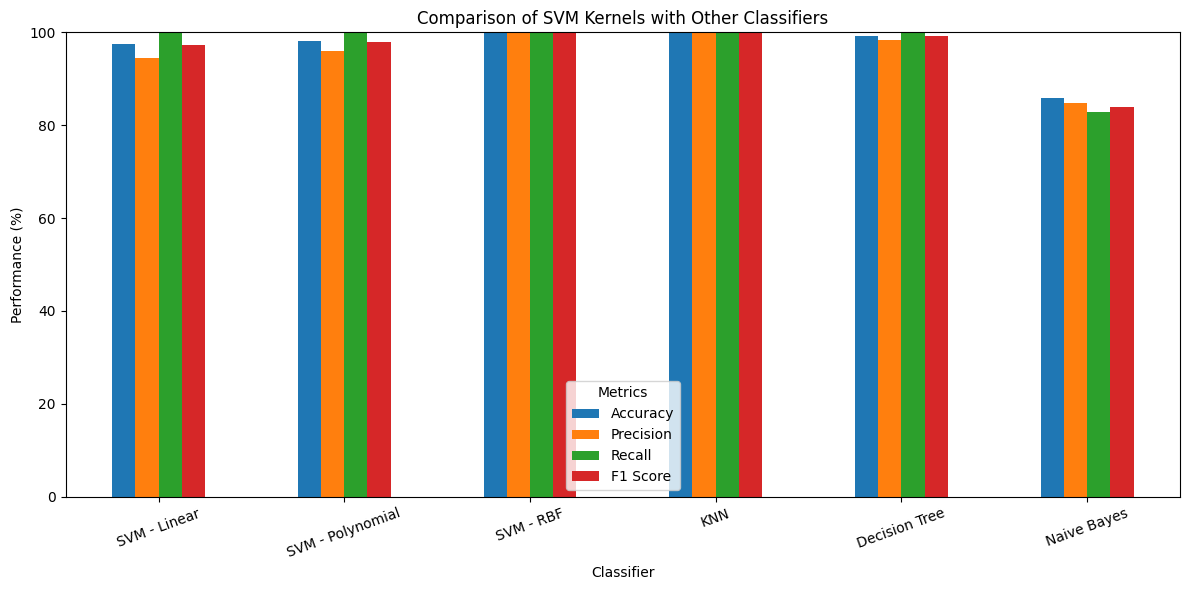

In [10]:
# ============================================================
# 9. BAR GRAPH
# ============================================================

plot_data = percentage_results.set_index("Model")

plot_data[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Comparison of SVM Kernels with Other Classifiers"
)

plt.xlabel("Classifier")

plt.ylabel("Performance (%)")

plt.ylim(0, 100)

plt.xticks(rotation=20)

plt.legend(title="Metrics")

plt.tight_layout()

plt.show()

In [11]:
# ============================================================
# 10. CLASSIFICATION REPORT
# ============================================================

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    print("\n")
    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "Genuine",
                "Forged"
            ],
            zero_division=0
        )
    )



SVM - Linear
              precision    recall  f1-score   support

     Genuine       1.00      0.95      0.98       153
      Forged       0.95      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.98      0.97       275
weighted avg       0.98      0.97      0.97       275



SVM - Polynomial
              precision    recall  f1-score   support

     Genuine       1.00      0.97      0.98       153
      Forged       0.96      1.00      0.98       122

    accuracy                           0.98       275
   macro avg       0.98      0.98      0.98       275
weighted avg       0.98      0.98      0.98       275



SVM - RBF
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00       153
      Forged       1.00      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00     